In [65]:
import json
with open("../../outputs/hpo/fixed_hpo/outputs.json", "r") as f:
    hpo_data = json.load(f)
with open("../../hpo/baseline_metrics.json", "r") as f:
    baseline_metrics = json.load(f)
print(baseline_metrics)

{'promoter_no_tata': {'mean': 0.7405125345514904, 'std': 0.009662391230587769, 'metric': 'val/mcc'}, 'H4K20me1': {'mean': 0.5436134490332801, 'std': 0.013482136412023275, 'metric': 'val/mcc'}, 'H3K4me2': {'mean': 0.4716739376444533, 'std': 0.008945281075275117, 'metric': 'val/mcc'}, 'promoter_all': {'mean': 0.7141917427818367, 'std': 0.00508178985524451, 'metric': 'val/mcc'}, 'H3K4me1': {'mean': 0.4022766753904484, 'std': 0.009675223035841117, 'metric': 'val/mcc'}, 'enhancers': {'mean': 0.4880958547902169, 'std': 0.004728348458373176, 'metric': 'val/mcc'}, 'promoter_tata': {'mean': 0.7066635549360011, 'std': 0.013680262966218592, 'metric': 'val/mcc'}, 'splice_sites_acceptors': {'mean': 0.505822948120817, 'std': 0.011420454124284, 'metric': 'val/mcc'}, 'H2AFZ': {'mean': 0.39551646712870925, 'std': 0.007267844338595689, 'metric': 'val/mcc'}, 'H3K4me3': {'mean': 0.6122926753274245, 'std': 0.013124333203499308, 'metric': 'val/mcc'}, 'H3K9ac': {'mean': 0.5031925326397123, 'std': 0.010754890

In [66]:
trial_scores = {}
for trial in hpo_data.keys():
    trial_scores[trial] = {}

for dataset_name in ("nt_benchmark", "genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"):
    def get_tasks(trial):
        global dataset_name
        if dataset_name == "chromatin_profile_prediction":
            cpp = trial.get("chromatin_profile_prediction")
            if cpp is not None:
                return {"chromatin_profile_prediction": cpp}
            else:
                return None
        else:
            return trial.get(dataset_name)

    for trial in hpo_data.keys():
        tasks = get_tasks(hpo_data[trial])

        if tasks is not None:
            for name, val in tasks.items():
                if name == "pretraining": 
                    continue
                trial_scores[trial][name] = val[0][baseline_metrics[name]["metric"]]

In [67]:
# Cleanup
for trial_key in list(trial_scores.keys()):
    if len(trial_scores[trial_key]) != 30:
        del trial_scores[trial_key]

In [68]:
# Turn it into df
import pandas as pd
df = pd.DataFrame.from_dict(trial_scores, orient="index")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 21 entries, 0 to 20
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   splice_sites_acceptors            21 non-null     float64
 1   H3K27me3                          21 non-null     float64
 2   splice_sites_all                  21 non-null     float64
 3   H3K4me2                           21 non-null     float64
 4   H2AFZ                             21 non-null     float64
 5   H3K4me1                           21 non-null     float64
 6   H3K27ac                           21 non-null     float64
 7   H3K9me3                           21 non-null     float64
 8   H3K4me3                           21 non-null     float64
 9   enhancers_types                   21 non-null     float64
 10  promoter_all                      21 non-null     float64
 11  enhancers                         21 non-null     float64
 12  promoter_tata  

In [69]:
z_scores = df.apply(lambda col: (col - baseline_metrics[col.name]["mean"]) / baseline_metrics[col.name]["std"], axis=0)

In [71]:
records = (df == df.max()).sum(axis=1)
records_list = sorted(list(records), reverse=True)
print([*records_list]) # The sum of records_list is higher than 30 because when there's a tie, it gives a record to all the tied trials.

[5, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 0, 0, 0, 0, 0, 0]


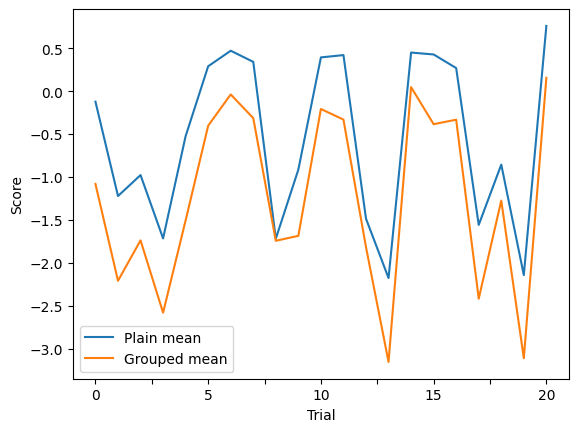

In [83]:
# Plot the grouped mean vs plain mean
from matplotlib import pyplot as plt

TASKS_GROUPS = {
    "histone": [
        "H2AFZ",
        "H3K27ac",
        "H3K27me3",
        "H3K36me3",
        "H3K4me1",
        "H3K4me2",
        "H3K4me3",
        "H3K9ac",
        "H3K9me3",
        "H4K20me1",
    ],
    "promoter": [
        "promoter_all",
        "promoter_tata",
        "promoter_no_tata",
        "human_nontata_promoters",
    ],
    "enhancers": [
        "enhancers",
        "enhancers_types",
        "dummy_mouse_enhancers_ensembl",
        "human_enhancers_cohn",
        "human_enhancers_ensembl",
        "human_ensembl_regulatory",
        "human_ocr_ensembl",
        "drosophila_enhancers_stark"
    ],
    "splicing": [
        "splice_sites_all",
        "splice_sites_donors",
        "splice_sites_acceptors",
    ],
    "general_genomic_content": [
        "demo_coding_vs_intergenomic_seqs",
        "demo_human_or_worm",
    ],
    "gene_finding": ["gene_finding"],
    "cpg_methylation": ["cpg_methylation"],
    "chromatin_profile_prediction": ["chromatin_profile_prediction"]
}

groups = [z_scores[TASKS_GROUPS[group]].mean(axis=1) for group in TASKS_GROUPS]
grouped_means = pd.concat(groups, axis=1).mean(axis=1) # The axis for pd.concat specifies the resulting series direction, I wanna concatenate the series as columns
z_scores["grouped_means"] = grouped_means
z_scores["plain_means"] = z_scores.mean(axis=1)

ax = z_scores[["plain_means", "grouped_means"]].plot(xlabel="Trial", ylabel="Score")
ax.legend(["Plain mean", "Grouped mean"])

In [76]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
)
import optuna

study = optuna.load_study(study_name="hpo", storage="sqlite:///../../outputs/hpo/fixed_hpo/optuna.db")
plot_optimization_history(study).show()
plot_param_importances(study).show()
print(study.best_params)

{'overlapping_segments_canonicalization': 'both_break', 'annotations_level': 2, 'include_cdjv_segments': 'false', 'include_pseudogenes': 'true', 'transformation': 'rc'}
